Иерархический кластерный анализ - задача_2_Economics of Cities


Определить число кластеров и обосновать свой выбор.

Разбить объекты на кластеры. 

Предложить и обосновать интерпретацию кластеров.

Загрузка данных и первичный просмотр

In [255]:
#  Активируем библиотеки

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt

import os

In [256]:
#  Импорт данных

#  index_col указывает, какую колонку в данных использовать как индекс

df = pd.read_csv(
    "./задача_2_Economics of Cities/Econom_Cities_data.csv",
    sep=";",
    index_col="City",
    decimal=",",  # запятая как десятичный разделитель
)

df.describe(include="all")

,Work,Price,Salary
count,48.000000,48.000000,48.000000
mean,1384.958333,68.860417,-378.727083
std,2404.897007,21.784659,2027.338052
min,-9999.000000,30.300000,-9999.000000
25%,1740.750000,49.650000,12.250000
50%,1834.500000,70.500000,40.300000
75%,1972.750000,81.700000,58.700000
max,2375.000000,115.500000,100.000000


Видно что есть выбросы с значением -9999, надо убрать;

Посмотрев в файле это [Cairo, Jakarta]

In [257]:
df.loc[["Cairo", "Jakarta"]]

,Work,Price,Salary
City,,,
Cairo,-9999,37.1,-9999.0
Jakarta,-9999,43.6,-9999.0


In [258]:
df_clean = df.drop(index=["Cairo", "Jakarta"])
print(df.shape, "->", df_clean.shape)  # (48, 3) -> (46, 3)
print(df_clean.describe(include="all"))

(48, 3) -> (46, 3)
              Work       Price      Salary
count    46.000000   46.000000   46.000000
mean   1879.913043   70.100000   39.545652
std     174.342552   21.389177   24.757703
min    1583.000000   30.300000    2.700000
25%    1745.250000   51.775000   14.375000
50%    1849.000000   70.950000   43.650000
75%    1976.250000   81.900000   59.700000
max    2375.000000  115.500000  100.000000


Чтобы переменная Work не доминировала стандартизируем переменные, применив StandartScaler

In [259]:
from sklearn import preprocessing

# Выбираем один из вариантов стандартизации

stand_1 = preprocessing.StandardScaler()

# вычисляем параметры стандартизации (они сохраняются внутри объекта norm)
stand_1.fit(df_clean)
# преобразуем данные
X = stand_1.transform(df_clean)
# Получаем объект X -- матрицу класса numpy.ndarray.
# Преобразуем её в объект класса pandas.DataFrame.
X = pd.DataFrame(X, index=df_clean.index, columns=df_clean.columns)

In [260]:
X.describe()

,Work,Price,Salary
count,4.600000e+01,4.600000e+01,4.600000e+01
mean,6.365681e-16,-4.247810e-16,1.061952e-16
std,1.011050e+00,1.011050e+00,1.011050e+00
min,-1.721863e+00,-1.881316e+00,-1.504695e+00
25%,-7.809400e-01,-8.662088e-01,-1.027914e+00
50%,-1.792714e-01,4.017885e-02,1.676125e-01
75%,5.586788e-01,5.577770e-01,8.230592e-01
max,2.871116e+00,2.146023e+00,2.468822e+00


Все получилось std ~ 1.0, mean ~ 0.0

In [261]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

link = linkage(X, "ward", "euclidean")
print(link.shape)  # ожидаем (45, 4)
link

(45, 4)


array([[20.        , 33.        ,  0.13000932,  2.        ],
       [26.        , 44.        ,  0.20992596,  2.        ],
       [25.        , 28.        ,  0.24101549,  2.        ],
       [ 6.        , 37.        ,  0.26638013,  2.        ],
       [ 4.        , 39.        ,  0.27962161,  2.        ],
       [ 2.        , 17.        ,  0.28619313,  2.        ],
       [ 7.        , 43.        ,  0.31145704,  2.        ],
       [10.        , 11.        ,  0.31305006,  2.        ],
       [ 1.        , 30.        ,  0.3489377 ,  2.        ],
       [18.        , 34.        ,  0.38756772,  2.        ],
       [ 0.        , 50.        ,  0.419298  ,  3.        ],
       [12.        , 45.        ,  0.44645167,  2.        ],
       [ 9.        , 46.        ,  0.45306282,  3.        ],
       [36.        , 54.        ,  0.4905399 ,  3.        ],
       [13.        , 31.        ,  0.50930475,  2.        ],
       [ 8.        , 23.        ,  0.54142314,  2.        ],
       [ 5.        , 16.

In [262]:
c = link[:, 2][1]
for i in range( len(link[:, 2])):

    print(f"{link[:,2][i]:.2f} | {abs(c - link[:,2][i]):.2f} | {link[:,2][i]/c:.2f}")
    c = link[:, 2][i]

0.13 | 0.08 | 0.62
0.21 | 0.08 | 1.61
0.24 | 0.03 | 1.15
0.27 | 0.03 | 1.11
0.28 | 0.01 | 1.05
0.29 | 0.01 | 1.02
0.31 | 0.03 | 1.09
0.31 | 0.00 | 1.01
0.35 | 0.04 | 1.11
0.39 | 0.04 | 1.11
0.42 | 0.03 | 1.08
0.45 | 0.03 | 1.06
0.45 | 0.01 | 1.01
0.49 | 0.04 | 1.08
0.51 | 0.02 | 1.04
0.54 | 0.03 | 1.06
0.55 | 0.01 | 1.01
0.56 | 0.01 | 1.02
0.65 | 0.10 | 1.17
0.71 | 0.05 | 1.08
0.71 | 0.01 | 1.01
0.73 | 0.02 | 1.03
0.81 | 0.08 | 1.11
0.82 | 0.01 | 1.01
0.83 | 0.01 | 1.02
0.84 | 0.00 | 1.00
0.92 | 0.08 | 1.10
1.01 | 0.09 | 1.10
1.07 | 0.07 | 1.06
1.10 | 0.02 | 1.02
1.19 | 0.09 | 1.08
1.27 | 0.08 | 1.07
1.35 | 0.08 | 1.06
1.53 | 0.19 | 1.14
1.60 | 0.07 | 1.04
1.65 | 0.05 | 1.03
1.67 | 0.02 | 1.01
1.91 | 0.24 | 1.14
2.91 | 1.00 | 1.53
2.99 | 0.08 | 1.03
3.40 | 0.41 | 1.14
3.66 | 0.26 | 1.08
4.86 | 1.20 | 1.33
5.06 | 0.20 | 1.04
12.40 | 7.34 | 2.45


видно что есть несколько сильных скачков;

Самый сильный последний ~7.4 к = 6 

так же есть 1.2 k = 4.5 
 
и 1.14 k = 3.5 

Также есть еще более мелкий но относительно сильный рывок 1.00  k = 2.5

Это самые сильные рывки  при слияниях

Посмотрим на них с помощью дендрограммы

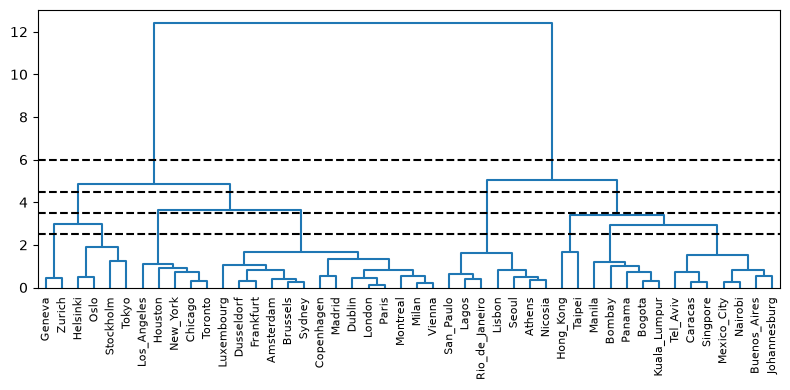

In [263]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

fig = plt.figure(figsize=(8, 4))
dn = dendrogram(
    link, labels=X.index.tolist(), leaf_rotation=90, color_threshold=-1
)  # -1 = без авто-раскраски
plt.axhline(y=6, c="k", ls="--")  # кандидат k=2
plt.axhline(y=4.5, c="k", ls="--")  # кандидат k=3
plt.axhline(y=3.5, c="k", ls="--")  # кандидат k=4
plt.axhline(y=2.5, c="k", ls="--")  # кандидат k=5
plt.tight_layout()
plt.show()

# Видно что разбиение на 2 кластера дает нам картинку дорогих и дешевых городов
# Разделение на большее число кластеров - скорее описывает различие внутри кластеров из первого разбиения, но не так однозначно друг от друга

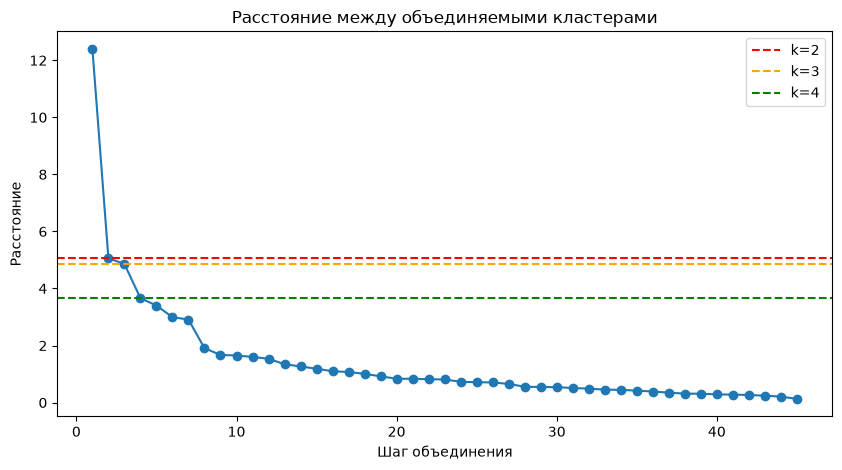

In [264]:
dist = link[:, 2]
dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1)
plt.figure(figsize=(10, 5))
plt.plot(idxs, dist_rev, marker="o")
plt.title("Расстояние между объединяемыми кластерами")
plt.xlabel("Шаг объединения")
plt.ylabel("Расстояние")
plt.axhline(5.06, c="r", ls="--", label="k=2")
plt.axhline(4.86, c="orange", ls="--", label="k=3")
plt.axhline(3.66, c="g", ls="--", label="k=4")
plt.legend()
plt.show()

### Видим что самый сильный скачок происходит при k = 2, это согласуется с дендраграммой - разбивает на 2 кластера с "дорогими городами" и "дешевыми"

### также есть скачки при к = [3, 4] но их интерпретация уже отличается

In [265]:
# Финальное разбиение
df_clean["cluster"] = fcluster(link, 2, criterion="maxclust")

# Размеры кластеров
print(f"Размеры кластеров {df_clean["cluster"].value_counts()}\n")

# Средние по кластерам
print(f"Средние по кластерам \n{df_clean.groupby("cluster")[["Work", "Price", "Salary"]].mean()}\n")

# Общие средние для сравнения
print(f"Общие средние для сравнения:\n{df_clean[["Work", "Price", "Salary"]].mean()}")

# Состав
for k in [1, 2]:
    print(f"\nКластер {k}:")
    print(df_clean[df_clean["cluster"] == k].index.tolist())

Размеры кластеров cluster
1    25
2    21
Name: count, dtype: int64

Средние по кластерам 
                Work      Price     Salary
cluster                                   
1        1789.240000  84.972000  59.032000
2        1987.857143  52.395238  16.347619

Общие средние для сравнения:
Work      1879.913043
Price       70.100000
Salary      39.545652
dtype: float64

Кластер 1:
['Amsterdam', 'Brussels', 'Chicago', 'Copenhagen', 'Dublin', 'Dusseldorf', 'Frankfurt', 'Geneva', 'Helsinki', 'Houston', 'London', 'Los_Angeles', 'Luxembourg', 'Madrid', 'Milan', 'Montreal', 'New_York', 'Oslo', 'Paris', 'Stockholm', 'Sydney', 'Tokyo', 'Toronto', 'Vienna', 'Zurich']

Кластер 2:
['Athens', 'Bogota', 'Bombay', 'Buenos_Aires', 'Caracas', 'Hong_Kong', 'Johannesburg', 'Kuala_Lumpur', 'Lagos', 'Lisbon', 'Manila', 'Mexico_City', 'Nairobi', 'Nicosia', 'Panama', 'Rio_de_Janeiro', 'San_Paulo', 'Seoul', 'Singpore', 'Taipei', 'Tel_Aviv']


## Интерпретация кластеров
---
Общие средние для сравнения:
- Work      1879.913043
- Price       70.100000
- Salary      39.545652

---

## Кластер 1 - дорогие города

Цены и зарплаты выше средних:
- Price = 84.9 на ~21%
- Salary = 59.03 на ~49%
- Но работают там меньше Work 1789 на ~5%
  
`Смотря на состав этого кластера видно крупные города, и мировые столицы/экономические центры `

```py
['Amsterdam', 'Brussels', 'Chicago', 'Copenhagen', 'Dublin', 'Dusseldorf', 'Frankfurt', 'Geneva', 'Helsinki', 'Houston', 'London', 'Los_Angeles', 'Luxembourg', 'Madrid', 'Milan', 'Montreal', 'New_York', 'Oslo', 'Paris', 'Stockholm', 'Sydney', 'Tokyo', 'Toronto', 'Vienna', 'Zurich']
```

Получается города развитых экономик с высокими ценами и высокими зарплатами — дорогие мировые центры

---

## Кластер 2 - дешевые города
Цены и зарплаты ниже средних но при этом работают больше:
- Price = 52.3 на ~25%
- Salary = 16.34 на ~60%
- Работают больше Work 1987 на ~5%

`Смотря на состав этого кластера видно города с низкими ценами и низкими зарплатами;
при этом работают в них больше — то есть уровень оплаты труда ниже.`

```py
['Athens', 'Bogota', 'Bombay', 'Buenos_Aires', 'Caracas', 'Hong_Kong', 'Johannesburg', 'Kuala_Lumpur', 'Lagos', 'Lisbon', 'Manila', 'Mexico_City', 'Nairobi', 'Nicosia', 'Panama', 'Rio_de_Janeiro', 'San_Paulo', 'Seoul', 'Singpore', 'Taipei', 'Tel_Aviv']
```





## Вывод по задаче

1. Число кластеров: выбрано k = 2.
   Обоснование: на дендрограмме и на графике каменистой осыпи самый сильный скачок наблюдается между 5.06 и 12.40 (скачок +7.34, то есть в ~2.45 раза). 
   Горизонтальная линия на высоте ~ 6 пересекает ровно две крупные ветки дерева. Скачки для k = 3 и k = 4 существенно слабее (в 1.33 и в 1.14), поэтому разбиение на большее число кластеров статистически менее обосновано.

2. Разбиение на кластеры: применён `fcluster(link, 2, criterion='maxclust')`. Получено два кластера размерами 25 и 21 город.

3. Интерпретация:
   - Кластер 1 — дорогие города с высоким уровнем жизни (Price ≈ 85, Salary ≈ 59 при общих средних 70 и 39.5);
   - Кластер 2 — города с низкими доходами и ценами (Salary ≈ 16.3, Price ≈ 52.4).

   Границы кластеров проходят не по географии, а по уровню цен и зарплат, что соответствует экономической постановке задачи.